# Применение глубокого обучения с подкреплением к алгоритмической торговле на основе нейронной сети LSTM

In [ ]:
import torch
import torch.nn as nn
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import pandas as pd
from collections import deque
import random
from torch.optim import Adam
from sklearn.preprocessing import MinMaxScaler

In [ ]:
# Загрузка и подготовка данных по акциям Apple (AAPL) период: с 1 апреля 2003 по 31 марта 2024 и загрузка данных по доходности 10-летних казначейских облигаций США (^TNX),
# чтобы использовать как proxy для безрисковой ставки
def load_data():
    apple = yf.download('AAPL', start='2003-04-01', end='2024-03-31')
    fed_rate = yf.download('^TNX', start='2003-04-01', end='2024-03-31')

    # Объединение данных в один DataFrame
    # Берем только цены закрытия (Close) из обоих наборов
    data = apple[['Close']].join(fed_rate[['Close']], how='outer', rsuffix='_rate')

    # Переименовываем столбцы
    data.columns = ['price', 'risk_free_rate']

    # Заполнение пропущенных значений:заполнение последним известным значением и удаление оставшихся
    data = data.ffill().dropna()

    # Нормализация данных с помощью MinMaxScaler приводим значения к диапазону [0, 1]
    scaler = MinMaxScaler()

    # Применяем нормализацию к обоим столбцам и создаем новые столбцы
    data[['price_scaled', 'rate_scaled']] = scaler.fit_transform(data[['price', 'risk_free_rate']])

    return data, scaler

In [ ]:
# Класс среды для обучения с подкреплением в торговле
class TradingEnvironment:
    def __init__(self, data, window_size=30):# Инициализация среды
        self.data = data  # DataFrame с ценой акции и безрисковой ставкой
        self.window_size = window_size  # Размер окна для исторических данных
        self.current_step = window_size  # Текущий шаг
        self.max_steps = len(data) - 1  # Максимальное количество шагов
        self.done = False  # Флаг завершения эпизода
        # Размер состояния: цены + ставки + волатильность
        self.state_size = window_size * 2 + 1

    def reset(self):
        # Сброс среды к начальному состоянию:
        self.current_step = self.window_size  # Возвращаем к началу
        self.done = False  # Сбрасываем флаг завершения
        return self._get_state()  # Возвращаем начальное состояние

    def _get_state(self):
        # Получение текущего состояния среды
        # Берем нормализованные цены за окно window_size
        prices = self.data['price_scaled'].values[self.current_step-self.window_size:self.current_step]

        # Берем нормализованные ставки за окно window_size
        rates = self.data['rate_scaled'].values[self.current_step-self.window_size:self.current_step]

        # Расчет волатильности:
        # вычисляем дневные доходности (разница цен / предыдущая цена)
        # считаем стандартное отклонение доходностей как меру волатильности
        returns = np.diff(prices) / prices[:-1] if len(prices) > 1 else np.array([0])
        volatility = np.std(returns) if len(returns) > 0 else 0

        # объединение цен, ставок и волатильности в один массив
        return np.concatenate([prices, rates, [volatility]])

    def step(self, action):
        # Выполнение шага в среде
        # Проверка, что эпизод не завершен
        if self.done:
            raise Exception("Episode is done, call reset()")

        # Получаем текущую и следующую цены
        current_price = self.data['price'].iloc[self.current_step]
        next_price = self.data['price'].iloc[self.current_step + 1]

        # Расчет доходности за шаг
        ret = (next_price - current_price) / current_price

        # Преобразование годовой безрисковой ставки в дневную
        risk_free = self.data['risk_free_rate'].iloc[self.current_step] / 100 / 252

        # Расчет коэффициента Шарпа
        # 1. Избыточная доходность (безрисковая ставка)
        # 2. Стандартное отклонение доходностей за последние 30 дней как риск
        # 3. Добавляем небольшое значение, чтобы избежать деления на 0
        excess_ret = ret - risk_free
        sharpe = excess_ret / (np.std(self.data['price'].pct_change().dropna().iloc[-30:]) + 1e-8)

        # Определение вознаграждения в зависимости от действия:
        reward = 0  # По умолчанию 0
        if action == 1:  # Действие "Купить"
            reward = sharpe  # Положительное вознаграждение при хорошем решении
        elif action == 2:  # Действие "Продать"
            reward = -sharpe  # Отрицательное вознаграждение при плохом решении

        # Переход к следующему шагу
        self.current_step += 1
        self.done = self.current_step >= self.max_steps  # Проверка завершения

        return self._get_state(), float(reward), self.done

In [ ]:
# Модель LSTM
class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, batch_first=True)# LSTM слой: принимает входной размер, размер скрытого состояния
        self.fc = nn.Linear(hidden_size, output_size)# Полносвязный слой для преобразования выхода LSTM в пространство действий

    def forward(self, x):
        # Пропускаем данные через LSTM слой
        x, _ = self.lstm(x)# x - выход LSTM (все скрытые состояния)
        return self.fc(x[:, -1, :]) # Берем только последний временной шаг и пропускаем через полносвязный слой


# Агент DQN с LSTM
class DQNAgent:
    def __init__(self, state_size, action_size):
        # Размеры состояния и пространства действий
        self.state_size = state_size
        self.action_size = action_size

        # Очередь для хранения опыта
        self.memory = deque(maxlen=2000)

        # Параметры
        self.gamma = 0.95    # Коэффициент дисконтирования будущих наград
        self.epsilon = 1.0   # Начальная вероятность случайного действия
        self.epsilon_min = 0.01  # Минимальное значение epsilon
        self.epsilon_decay = 0.995  # Скорость уменьшения epsilon
        self.batch_size = 64  # Размер батча для обучения

        # Инициализация моделей (основной и целевой)
        self.model = LSTMModel(1, 32, action_size)  # Входной размер 1 (цена), 32 нейрона в LSTM
        self.target_model = LSTMModel(1, 32, action_size)

        # Оптимизатор и функция потерь
        self.optimizer = Adam(self.model.parameters(), lr=0.001)
        self.criterion = nn.MSELoss()

        # Инициализация целевой модели
        self.update_target_model()

    def update_target_model(self):
        # Копирование весов из основной модели в целевую
        self.target_model.load_state_dict(self.model.state_dict())

    def remember(self, state, action, reward, next_state, done):
        # Сохранение опыта (состояние, действие, награда, следующее состояние, флаг завершения)
        self.memory.append((state, action, reward, next_state, done))

    def act(self, state):
        # Epsilon-greedy стратегия выбора действия
        if np.random.rand() <= self.epsilon:
            # Случайное действие для исследования
            return random.randrange(self.action_size)

        # Преобразование состояния в формат для модели (добавляем batch и feature размерности)
        state = torch.FloatTensor(state).unsqueeze(0).unsqueeze(-1)
        with torch.no_grad():  # Отключаем вычисление градиентов для инференса
            # Получаем Q-значения для всех действий
            act_values = self.model(state)
        # Выбираем действие с максимальным Q-значением
        return torch.argmax(act_values[0]).item()

    def replay(self):
        # Если в памяти недостаточно опыта, пропускаем обучение
        if len(self.memory) < self.batch_size:
            return

        # Выбираем случайный мини-батч из памяти
        minibatch = random.sample(self.memory, self.batch_size)

        # Разделяем данные на отдельные массивы
        states = np.array([x[0] for x in minibatch])
        actions = np.array([x[1] for x in minibatch])
        rewards = np.array([x[2] for x in minibatch])
        next_states = np.array([x[3] for x in minibatch])
        dones = np.array([x[4] for x in minibatch])

        # Конвертируем numpy массивы в PyTorch тензоры
        states = torch.FloatTensor(states).unsqueeze(-1)  # Добавляем размерность признака
        next_states = torch.FloatTensor(next_states).unsqueeze(-1)
        actions = torch.LongTensor(actions)
        rewards = torch.FloatTensor(rewards)
        dones = torch.FloatTensor(dones)

        # Получаем Q-значения для выбранных действий
        current_q = self.model(states).gather(1, actions.unsqueeze(1)).squeeze(1)

        # Вычисляем целевые Q-значения с использованием целевой модели
        with torch.no_grad():
            # Максимальное Q-значение для следующего состояния
            next_q = self.target_model(next_states).max(1)[0]
            # Уравнение Беллмана: target = reward + gamma * max Q(s',a') * (1 - done)
            target_q = rewards + (1 - dones) * self.gamma * next_q

        # Вычисляем потерю и обновляем модель
        self.optimizer.zero_grad()
        loss = self.criterion(current_q, target_q)  # MSE между текущими и целевыми Q-значениями
        loss.backward()  # Обратное распространение ошибки
        self.optimizer.step()  # Шаг оптимизации

        # Уменьшаем epsilon
        if self.epsilon > self.epsilon_min:
            self.epsilon *= self.epsilon_decay


# Функция обучения агента
def train_agent(data, episodes=50):
    # Создаем среду торговли и агента
    env = TradingEnvironment(data)
    agent = DQNAgent(env.state_size, 3)  # 3 действия: 0-ждать, 1-купить, 2-продать

    # История для отслеживания прогресса
    rewards_history = []  # Суммарные награды за эпизод
    sharpe_history = []  # Коэффициенты Шарпа за эпизод

    # Цикл по эпизодам обучения
    for e in range(episodes):
        state = env.reset()  # Сбрасываем среду
        total_reward = 0     # Суммарная награда за эпизод
        portfolio_value = 10000  # Начальная стоимость портфеля
        position = 0         # Текущая позиция (0 - нет позиции, 1 - есть позиция)
        returns = []         # Доходности для расчета коэффициента Шарпа

        # Цикл внутри одного эпизода
        while not env.done:
            # Выбираем действие
            action = agent.act(state)

            # Корректировка действия: нельзя продать, если нет позиции
            if position == 0 and action == 2:  # Действие "продать" (2)
                action = 0  # Заменяем на "ждать" (0)

            # Выполняем действие в среде
            next_state, reward, done = env.step(action)

            # Обновляем стоимость портфеля
            current_price = data['price'].iloc[env.current_step-1]
            next_price = data['price'].iloc[env.current_step]

            # Логика управления позицией:
            if action == 1 and position == 0:  # Покупаем
                position = 1
                shares = portfolio_value / current_price  # Количество купленных акций
                portfolio_value = shares * next_price    # Обновляем стоимость
            elif action == 2 and position == 1:  # Продаем
                position = 0
                shares = portfolio_value / current_price
                portfolio_value = shares * next_price
            elif position == 1:  # Держим позицию
                shares = portfolio_value / current_price
                portfolio_value = shares * next_price

            # Сохраняем доходность (в процентах от начального капитала)
            returns.append((portfolio_value - 10000) / 10000)

            # Сохраняем опыт в память агента
            agent.remember(state, action, reward, next_state, done)
            state = next_state  # Переходим в новое состояние
            total_reward += reward  # Обновляем суммарную награду

        # Расчет коэффициента Шарпа (мера риск-доходность)
        if len(returns) > 1:
            # Средняя безрисковая ставка за период
            risk_free = data['risk_free_rate'].iloc[env.window_size:env.current_step].mean() / 100 / 252
            # Избыточная доходность (над безрисковой ставкой)
            excess_returns = np.array(returns) - risk_free
            # Формула коэффициента Шарпа: средняя избыточная доходность / стандартное отклонение
            sharpe = np.mean(excess_returns) / (np.std(excess_returns) + 1e-8)  # +1e-8 для избежания деления на 0
            sharpe_history.append(sharpe)
        else:
            sharpe_history.append(0)  # Если недостаточно данных для расчета

        # Сохраняем и выводим результаты
        rewards_history.append(total_reward)
        agent.replay()  # Обучаем модель на накопленном опыте
        agent.update_target_model()  # Обновляем целевую модель

        # Вывод статистики по эпизоду
        print(f"Episode: {e+1}/{episodes}, Reward: {total_reward:.2f}, Sharpe: {sharpe_history[-1]:.4f}, Epsilon: {agent.epsilon:.2f}")

    return agent, rewards_history, sharpe_history


# Функция визуализации результатов обучения
def plot_results(rewards, sharpes):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    # График наград по эпизодам
    ax1.plot(rewards)
    ax1.set_title('Награды по эпизодам')
    ax1.set_xlabel('Эпизод')
    ax1.set_ylabel('Награда')

    # График коэффициента Шарпа по эпизодам
    ax2.plot(sharpes)
    ax2.set_title('Коэффициент Шарпа')
    ax2.set_xlabel('Эпизод')
    ax2.set_ylabel('Sharpe Ratio')

    plt.show()

[*********************100%***********************]  1 of 1 completed

Загрузка данных...



[*********************100%***********************]  1 of 1 completed
<ipython-input-30-b003dd2da80e>:21: RuntimeWarning: divide by zero encountered in divide
  returns = np.diff(prices) / prices[:-1] if len(prices) > 1 else np.array([0])
/usr/local/lib/python3.11/dist-packages/numpy/_core/_methods.py:185: RuntimeWarning: invalid value encountered in subtract
  x = asanyarray(arr - arrmean)



Обучение агента...
Episode: 1/50, Reward: 73.79, Sharpe: 1.1203, Epsilon: 0.99
Episode: 2/50, Reward: -15.03, Sharpe: 0.9909, Epsilon: 0.99
Episode: 3/50, Reward: -96.18, Sharpe: 1.0392, Epsilon: 0.99
Episode: 4/50, Reward: 155.59, Sharpe: 0.7695, Epsilon: 0.98
Episode: 5/50, Reward: 217.06, Sharpe: 0.7943, Epsilon: 0.98
Episode: 6/50, Reward: 59.33, Sharpe: 1.3836, Epsilon: 0.97
Episode: 7/50, Reward: 173.79, Sharpe: 0.9644, Epsilon: 0.97
Episode: 8/50, Reward: 103.56, Sharpe: 1.1515, Epsilon: 0.96
Episode: 9/50, Reward: 203.03, Sharpe: 0.9057, Epsilon: 0.96
Episode: 10/50, Reward: 44.99, Sharpe: 1.0405, Epsilon: 0.95
Episode: 11/50, Reward: 24.55, Sharpe: 1.0866, Epsilon: 0.95
Episode: 12/50, Reward: -40.93, Sharpe: 1.2196, Epsilon: 0.94
Episode: 13/50, Reward: -53.84, Sharpe: 0.9560, Epsilon: 0.94
Episode: 14/50, Reward: 98.92, Sharpe: 0.9046, Epsilon: 0.93
Episode: 15/50, Reward: 62.68, Sharpe: 1.2114, Epsilon: 0.93
Episode: 16/50, Reward: 168.41, Sharpe: 1.0539, Epsilon: 0.92
Epi

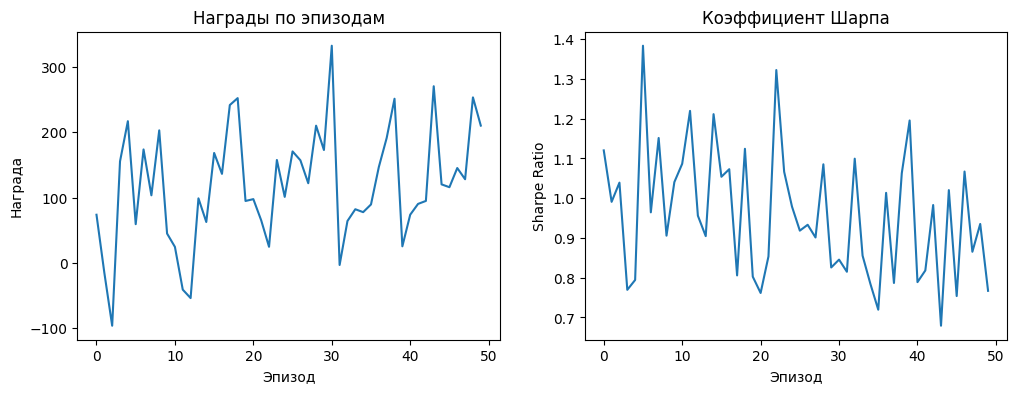

In [ ]:
# Основной блок
if __name__ == "__main__":
    # Загрузка данных
    print("Загрузка данных...")
    data, scaler = load_data()

    # Обучение агента
    print("\nОбучение агента...")
    agent, rewards, sharpes = train_agent(data, episodes=50)

    # Визуализация результатов
    plot_results(rewards, sharpes)

Агент демонстрирует прогресс в обучении, показывая положительные награды и приемлемый коэффициент Шарпа (>1.0 в половине случаев), однако результаты остаются нестабильными из-за избыточного исследования (высокий epsilon), что требует уменьшения epsilon.

In [ ]:
# Улучшенная функция расчета состояния
def _get_state(self):
    # Получаем нормализованные значения цен и процентных ставок за окно наблюдения
    prices = self.data['price_scaled'].values[self.current_step-self.window_size:self.current_step]
    rates = self.data['rate_scaled'].values[self.current_step-self.window_size:self.current_step]

    # Безопасный расчет доходности и волатильности с обработкой возможных ошибок
    with np.errstate(divide='ignore', invalid='ignore'):
        # Рассчитываем процентные изменения цен (доходность)
        returns = np.where(prices[:-1] != 0,
                         np.diff(prices) / prices[:-1],
                         0)
        # Рассчитываем волатильность как стандартное отклонение доходностей
        volatility = np.nanstd(returns) if len(returns) > 0 else 0
        # Защита от NaN значений
        volatility = 0 if np.isnan(volatility) else volatility

    # Возвращаем объединенный вектор состояния: цены, ставки и волатильность
    return np.concatenate([prices, rates, [volatility]])

# Улучшенная функция обучения агента
def train_agent(data, episodes=50):
    # Инициализация среды и агента
    env = TradingEnvironment(data)
    agent = DQNAgent(env.state_size, 3)  # 3 действия: ждать, купить, продать

    # Инициализация списков для хранения истории
    rewards_history = []  # История наград за эпизоды
    sharpe_history = []   # История коэффициентов Шарпа
    portfolio_values = [] # История значений портфеля

    # Цикл обучения по эпизодам
    for e in range(episodes):
        state = env.reset()  # Сброс среды в начальное состояние
        total_reward = 0     # Суммарная награда за эпизод
        portfolio_value = 10000  # Начальная стоимость портфеля
        position = 0         # Текущая позиция (0 - нет позиции, 1 - есть позиция)
        returns = []         # Список доходностей для расчета Шарпа

        # Цикл внутри одного эпизода
        while not env.done:
            # Выбор действия агентом
            action = agent.act(state)

            # Корректировка действия: нельзя продать, если нет позиции
            if position == 0 and action == 2:
                action = 0  # Заменяем продажу на бездействие

            # Выполнение действия в среде
            next_state, reward, done = env.step(action)

            # Обновление стоимости портфеля с защитой от деления на ноль
            current_price = data['price'].iloc[env.current_step-1]
            next_price = data['price'].iloc[env.current_step]

            if current_price > 0:  # Проверка на положительную цену
                # Логика управления позицией
                if action == 1 and position == 0:  # Покупка
                    position = 1
                    shares = portfolio_value / current_price
                    portfolio_value = shares * next_price
                elif action == 2 and position == 1:  # Продажа
                    position = 0
                    shares = portfolio_value / current_price
                    portfolio_value = shares * next_price
                elif position == 1:  # Удержание позиции
                    shares = portfolio_value / current_price
                    portfolio_value = shares * next_price

                # Сохранение доходности в процентах от начального капитала
                returns.append((portfolio_value - 10000) / 10000)

            # Сохранение опыта в память агента
            agent.remember(state, action, reward, next_state, done)
            # Переход в следующее состояние
            state = next_state
            # Накопление суммарной награды
            total_reward += reward

        # Улучшенный расчет коэффициента Шарпа
        if len(returns) > 1:
            # Расчет безрисковой ставки (средней за период)
            risk_free = data['risk_free_rate'].iloc[env.window_size:env.current_step].mean() / 100 / 252
            # Расчет избыточной доходности
            excess_returns = np.array(returns) - risk_free
            # Расчет коэффициента Шарпа с защитой от деления на ноль
            sharpe = np.nanmean(excess_returns) / (np.nanstd(excess_returns) + 1e-8)
            # Защита от NaN значений
            sharpe = 0 if np.isnan(sharpe) else sharpe
        else:
            sharpe = 0  # Если недостаточно данных для расчета

        # Сохранение результатов эпизода
        rewards_history.append(total_reward)
        sharpe_history.append(sharpe)
        portfolio_values.append(portfolio_value)

        # Обучение агента на накопленном опыте
        agent.replay()
        # Обновление целевой модели
        agent.update_target_model()

        # Вывод статистики по эпизоду
        print(f"Episode: {e+1}/{episodes}, Reward: {total_reward:.2f}, "
              f"Sharpe: {sharpe:.4f}, Portfolio: ${portfolio_value:.2f}, "
              f"Epsilon: {agent.epsilon:.2f}")

    return agent, rewards_history, sharpe_history, portfolio_values

# Дополнительная функция визуализации результатов
def plot_combined_results(rewards, sharpes, portfolios):
    # Создание фигуры с тремя графиками
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 4))

    # График наград по эпизодам
    ax1.plot(rewards)
    ax1.set_title('Награды по эпизодам')
    ax1.set_xlabel('Эпизод')
    ax1.set_ylabel('Награда')
    ax1.grid(True)

    # График коэффициента Шарпа по эпизодам
    ax2.plot(sharpes)
    ax2.set_title('Коэффициент Шарпа')
    ax2.set_xlabel('Эпизод')
    ax2.set_ylabel('Sharpe Ratio')
    ax2.grid(True)

    # График стоимости портфеля по эпизодам
    ax3.plot(portfolios)
    ax3.set_title('Значение портфеля')
    ax3.set_xlabel('Эпизод')
    ax3.set_ylabel('Стоимость ($)')
    ax3.grid(True)

    # Оптимизация расположения графиков
    plt.tight_layout()
    plt.show()

<ipython-input-30-b003dd2da80e>:21: RuntimeWarning: divide by zero encountered in divide
  returns = np.diff(prices) / prices[:-1] if len(prices) > 1 else np.array([0])
/usr/local/lib/python3.11/dist-packages/numpy/_core/_methods.py:185: RuntimeWarning: invalid value encountered in subtract
  x = asanyarray(arr - arrmean)


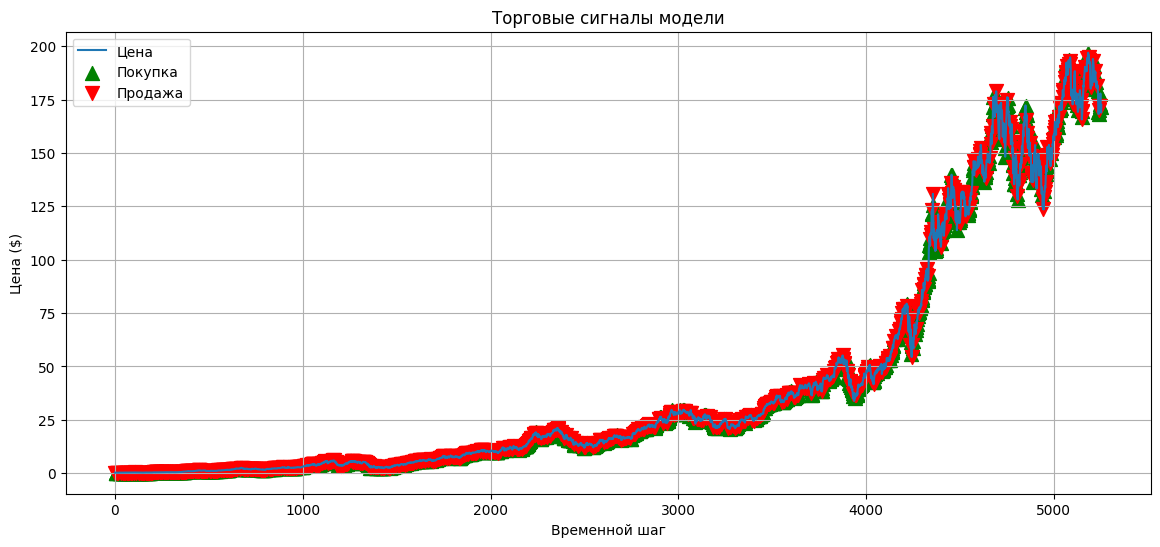

In [ ]:
# визуализация торговых решений
def plot_trading_signals(data, agent):
    env = TradingEnvironment(data)
    state = env.reset()
    prices = []
    actions = []

    while True:
        action = agent.act(state)
        next_state, _, done = env.step(action)

        prices.append(data['price'].iloc[env.current_step-1])
        actions.append(action)
        state = next_state

        if done:
            break

    plt.figure(figsize=(14, 6))
    plt.plot(prices, label='Цена')

    buy_signals = [i for i, a in enumerate(actions) if a == 1]
    sell_signals = [i for i, a in enumerate(actions) if a == 2]

    plt.scatter(buy_signals, [prices[i] for i in buy_signals],
               color='green', marker='^', s=100, label='Покупка')
    plt.scatter(sell_signals, [prices[i] for i in sell_signals],
               color='red', marker='v', s=100, label='Продажа')

    plt.title('Торговые сигналы модели')
    plt.xlabel('Временной шаг')
    plt.ylabel('Цена ($)')
    plt.legend()
    plt.grid()
    plt.show()

# Вызов функции
plot_trading_signals(data, agent)

[*********************100%***********************]  1 of 1 completed



Результаты тестирования (2022-01-01 - 2024-03-31):
Начальная сумма: $10000.00
Стратегия модели: $8993.35 (Доходность: -10.07%)
Buy&Hold стратегия: $9442.78 (Доходность: -5.57%)


<ipython-input-39-be2ea4e86f95>:70: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(f"Buy&Hold стратегия: ${float(buy_hold[-1]):.2f} (Доходность: {((buy_hold[-1]/initial_value)-1)*100:.2f}%)")


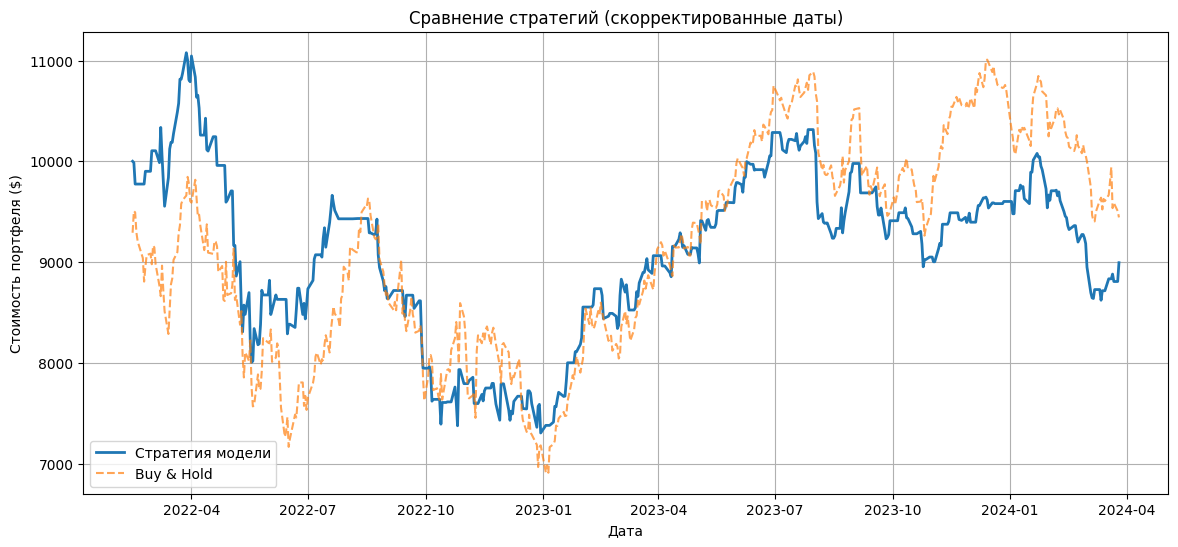


Дополнительная статистика:
Количество дней тестирования: 531
Максимальная стоимость портфеля: $11077.33
Минимальная стоимость портфеля: $7303.32
Максимальная просадка: -34.07%


In [ ]:
# Загрузка и подготовка тестовых данных
test_data = yf.download('AAPL', start='2022-01-01', end='2024-03-31')[['Close']]
test_data.columns = ['price']
test_data['risk_free_rate'] = data['risk_free_rate'].mean()
test_data[['price_scaled', 'rate_scaled']] = scaler.transform(test_data[['price', 'risk_free_rate']])

# Функция тестирования модели с фиксированными датами
def test_model(data, agent, initial_value=10000):
    env = TradingEnvironment(data)
    state = env.reset()
    portfolio_value = initial_value
    position = 0
    history = []
    dates = []

    while True:
        action = agent.act(state)

        # Корректировка действий
        if position == 0 and action == 2: action = 0
        if position == 1 and action == 1: action = 0

        # Сохраняем текущую дату
        current_date = data.index[env.current_step-1]
        current_price = float(data['price'].iloc[env.current_step-1])

        # Обновление портфеля
        if action == 1 and position == 0:
            position = 1
            shares = portfolio_value / current_price
        elif action == 2 and position == 1:
            position = 0
            shares = portfolio_value / current_price

        if position == 1:
            next_price = float(data['price'].iloc[env.current_step])
            portfolio_value = shares * next_price

        # Сохраняем историю
        history.append(portfolio_value)
        dates.append(current_date)

        # Переход к следующему состоянию
        next_state, _, done = env.step(action)
        state = next_state

        if done:
            break

    # Создаем DataFrame с фиксированными датами
    result = pd.DataFrame({
        'date': dates,
        'portfolio_value': history
    }).set_index('date')

    return float(portfolio_value), result

# Тестирование модели
initial_value = 10000
model_value, model_history = test_model(test_data, agent, initial_value)

# Расчет Buy&Hold стратегии
buy_hold = initial_value * (test_data['price'] / test_data['price'].iloc[0])
buy_hold = buy_hold[model_history.index]  # Фильтруем по тем же датам

# Вывод результатов
print(f"\nРезультаты тестирования (2022-01-01 - 2024-03-31):")
print(f"Начальная сумма: ${initial_value:.2f}")
print(f"Стратегия модели: ${model_value:.2f} (Доходность: {((model_value/initial_value)-1)*100:.2f}%)")
print(f"Buy&Hold стратегия: ${float(buy_hold[-1]):.2f} (Доходность: {((buy_hold[-1]/initial_value)-1)*100:.2f}%)")

# Визуализация
plt.figure(figsize=(14, 6))

# График стратегии модели
plt.plot(model_history.index, model_history['portfolio_value'],
         label='Стратегия модели', linewidth=2)

# График Buy&Hold
plt.plot(model_history.index, buy_hold,
         label='Buy & Hold', alpha=0.7, linestyle='--')

plt.title('Сравнение стратегий (скорректированные даты)')
plt.xlabel('Дата')
plt.ylabel('Стоимость портфеля ($)')
plt.legend()
plt.grid()
plt.show()

# Дополнительный анализ
print("\nДополнительная статистика:")
print(f"Количество дней тестирования: {len(model_history)}")
print(f"Максимальная стоимость портфеля: ${model_history['portfolio_value'].max():.2f}")
print(f"Минимальная стоимость портфеля: ${model_history['portfolio_value'].min():.2f}")

# Расчет максимальной просадки
peak = model_history['portfolio_value'].cummax()
drawdown = (model_history['portfolio_value'] - peak) / peak
max_drawdown = drawdown.min() * 100
print(f"Максимальная просадка: {max_drawdown:.2f}%")